In [9]:
# Importing Libraries
import ast
import pandas as pd
import matplotlib.pyplot as plt  
import seaborn as sns
from datasets import load_dataset


# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [2]:
df_DA_US = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'United States')]

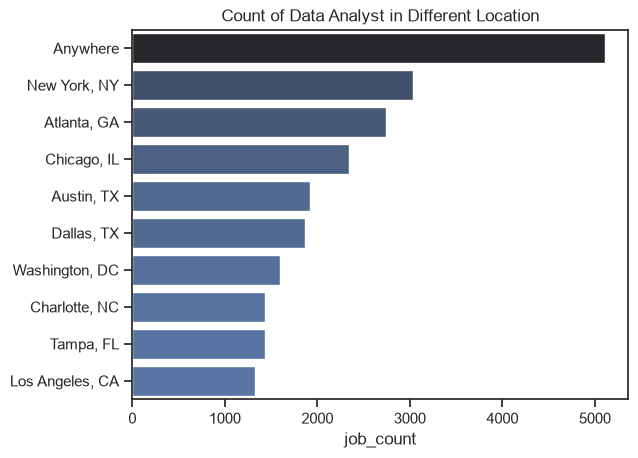

In [23]:
df_plot = df_DA_US['job_location'].value_counts().head(10).to_frame()

sns.set_theme(style='ticks')
sns.barplot(data=df_plot, x='count', y='job_location', hue='count', palette='dark:b_r', legend=False)
plt.title('Count of Data Analyst in Different Location')
plt.ylabel('')
plt.xlabel('job_count')
plt.show()

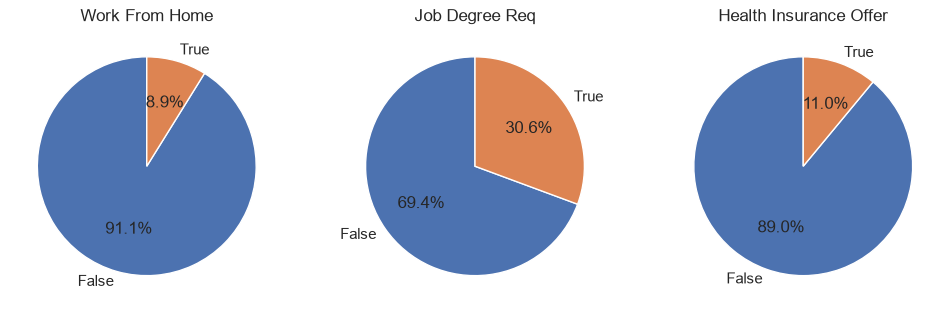

In [20]:
fig, ax = plt.subplots(1, 3)
fig.set_size_inches(12, 5)

dict_columns={
    'job_work_from_home': 'Work From Home',
    'job_no_degree_mention': 'Job Degree Req',
    'job_health_insurance': 'Health Insurance Offer'
}

for i, (column, title) in enumerate(dict_columns.items()):
    ax[i].pie(df[column].value_counts(), startangle=90, autopct='%1.1f%%', labels=('False', 'True'))
    ax[i].set_title(title)

plt.show()

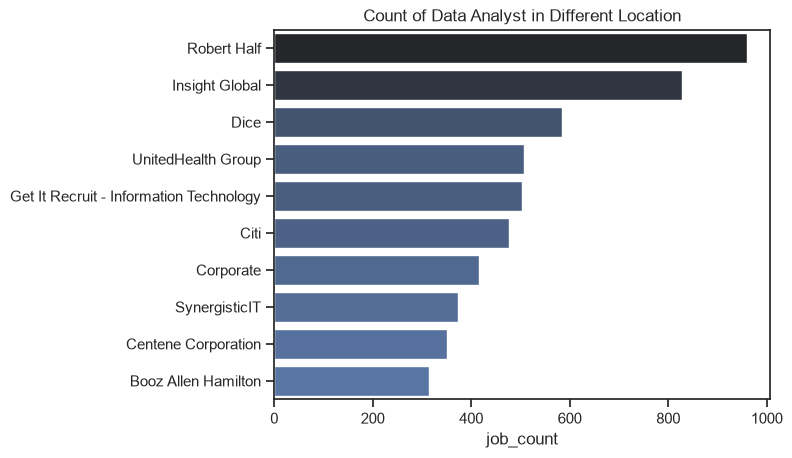

In [25]:
df_plot = df_DA_US['company_name'].value_counts().head(10).to_frame()

sns.set_theme(style='ticks')
sns.barplot(data=df_plot, x='count', y='company_name', hue='count', palette='dark:b_r', legend=False)
plt.title('Count of Data Analyst in Different Location')
plt.ylabel('')
plt.xlabel('job_count')
plt.show()